# 组员 D：Q4 城市差异、Q5 综合特征聚类

运行方式：打开本文件后选择 **Restart Kernel and Run All Cells**。所有计算都在本机运行，不访问网络。

主分析为1930–1932年白喉；Q4另有1915–1922对照。详细方法见`outputs/分析口径与待核对事项.md`。完整实现保留在`scripts/analyze.py`，本笔记本负责按步骤展示输入、计算和结果。

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / 'scripts/analyze.py').exists():
    raise RuntimeError('请从组员D_分析交付目录打开笔记本')
sys.path.insert(0, str(ROOT / 'scripts'))
import analyze
import verify
print('Python:', sys.executable)
print('工作目录:', ROOT)

Python: <local interpreter>
工作目录: D:\AllFolders\senior1\大数据原理与应用\大作业\组员D_分析交付


## 1. 读取已冻结的输入

`inputs`是原文件副本，防止上游更新后无法解释旧结果。CSV带BOM，用utf-8-sig读取。缺失留空，不填0。

In [2]:
data = pd.read_csv(analyze.SOURCE, encoding='utf-8-sig', parse_dates=['sunday_date'])
print('主表形状:', data.shape)
display(data.head())

主表形状: (3450, 29)


,city,sunday_date,year,flu_cases,flu_deaths,diph_cases,diph_deaths,polio_cases,tavg_avg,tmax_avg,...,np_polio_hits_weak,np_diph_hits,np_diph_hits_weak,np_pages,np_flu_rate,np_polio_rate,np_diph_rate,flu_rate_per100k,diph_rate_per100k,polio_rate_per100k
0,BALTIMORE,1915-01-03,1915,NaN,NaN,32.0,2.0,NaN,35.49,44.47,...,1,1,0,68,0.00,0.0,1.47,NaN,4.95,NaN
1,BALTIMORE,1915-01-10,1915,NaN,NaN,36.0,4.0,NaN,36.88,45.31,...,3,2,0,68,1.47,0.0,2.94,NaN,5.57,NaN
2,BALTIMORE,1915-01-17,1915,NaN,NaN,31.0,1.0,NaN,38.07,46.05,...,1,1,0,68,2.94,0.0,1.47,NaN,4.80,NaN
3,BALTIMORE,1915-01-24,1915,NaN,NaN,39.0,4.0,NaN,31.44,38.26,...,0,0,0,68,0.00,0.0,0.00,NaN,6.04,NaN
4,BALTIMORE,1915-01-31,1915,NaN,NaN,27.0,4.0,NaN,32.05,37.44,...,2,1,0,68,0.00,0.0,1.47,NaN,4.18,NaN


## 2. 看覆盖，再确定比较范围

先检查各病种数据完整性，不能把缺失视为零病例。本次白喉覆盖较好。

In [3]:
display(data[data.year.between(1930,1932)].groupby('city')[['flu_rate_per100k','diph_rate_per100k','polio_rate_per100k','np_diph_rate','snow_sum']].count())

,flu_rate_per100k,diph_rate_per100k,polio_rate_per100k,np_diph_rate,snow_sum
city,,,,,
BALTIMORE,131,155,123,156,156
CLEVELAND,140,153,125,156,156
LOS ANGELES,152,153,135,156,156
MILWAUKEE,80,154,93,130,156
NEW YORK,152,154,152,156,156
WASHINGTON,98,156,103,156,156


## 3. Q4：按城市做4周平滑，再取共同有效周

完整4周才计算，不跨城市或研究时段滚动；六城使用同一批周。图中使用跨城z-score，表中保留原单位。

In [4]:
prepared = analyze.prepare_window(data, 1930, 1932)
summary, common, n_weeks = analyze.aggregate_common(prepared, ['population','diph_rate_per100k','np_diph_rate'])
print('共同有效周:', n_weeks)
display(summary)
display(analyze.zscore(summary))

共同有效周: 106


,population,diph_rate_per100k,np_diph_rate
city,,,
BALTIMORE,8.088643e+05,1.181934,0.000000
CLEVELAND,8.988033e+05,1.011698,0.000000
LOS ANGELES,1.257639e+06,1.534410,0.314693
MILWAUKEE,5.789276e+05,0.517241,1.467854
NEW YORK,6.969045e+06,1.125071,0.116910
WASHINGTON,4.998361e+05,1.746156,0.308137


,population,diph_rate_per100k,np_diph_rate
city,,,
BALTIMORE,-0.444683,-0.010621,-0.723899
CLEVELAND,-0.405727,-0.446190,-0.723899
LOS ANGELES,-0.250302,0.891233,-0.104747
MILWAUKEE,-0.544277,-1.711320,2.164072
NEW YORK,2.223523,-0.156112,-0.493881
WASHINGTON,-0.578534,1.433010,-0.117647


## 4. Q5：标准化后聚类

气温单位为华氏度（℉），降水与降雪单位为英寸。prcp_sum/snow_sum先对各站该周有效观测日求日均，再对站点平均，并非周累计；Q5再对共同有效周求时段均值。口径据2026-10-29用户转述答复确认，详见inputs/气象口径确认.md。人口、气候和报刊指标单位不同，逐列标准化后用Ward层次聚类。只有六城，仅比较K=2、3。轮廓系数用于比较当前候选，不证明真实类别。

In [5]:
features, cluster_rows, cluster_weeks = analyze.aggregate_common(prepared, analyze.FEATURES)
display(features)
for k in [2,3]:
    z, tree, labels, score = analyze.cluster(features, k)
    print('K=', k, '轮廓系数=', round(score,4), '分组=', dict(zip(features.index, labels)))

,diph_rate_per100k,np_diph_rate,tavg_avg,prcp_sum,snow_sum,population
city,,,,,,
BALTIMORE,1.181934,0.000000,56.645000,0.088585,0.029811,8.088643e+05
CLEVELAND,1.011698,0.000000,51.954623,0.083396,0.042830,8.988033e+05
LOS ANGELES,1.534410,0.314693,62.992736,0.049340,0.004340,1.257639e+06
MILWAUKEE,0.517241,1.467854,49.772642,0.074528,0.083491,5.789276e+05
NEW YORK,1.125071,0.116910,54.603019,0.095472,0.023491,6.969045e+06
WASHINGTON,1.746156,0.308137,57.255377,0.087170,0.032358,4.998361e+05


K= 2 轮廓系数= 0.3164 分组= {'BALTIMORE': 1, 'CLEVELAND': 1, 'LOS ANGELES': 1, 'MILWAUKEE': 2, 'NEW YORK': 1, 'WASHINGTON': 1}
K= 3 轮廓系数= 0.2325 分组= {'BALTIMORE': 1, 'CLEVELAND': 1, 'LOS ANGELES': 2, 'MILWAUKEE': 3, 'NEW YORK': 1, 'WASHINGTON': 1}


## 5. 生成全部结果

此步骤会重建outputs中的计算结果和两幅图，不修改inputs。对照分析与报告也在同一次运行生成。

{"q4_common_weeks": {"1915-1922": 110, "1930-1932": 106}, "q5_common_weeks": 106, "k": 2, "silhouette": 0.31640598008316495, "min_ari": -0.2}


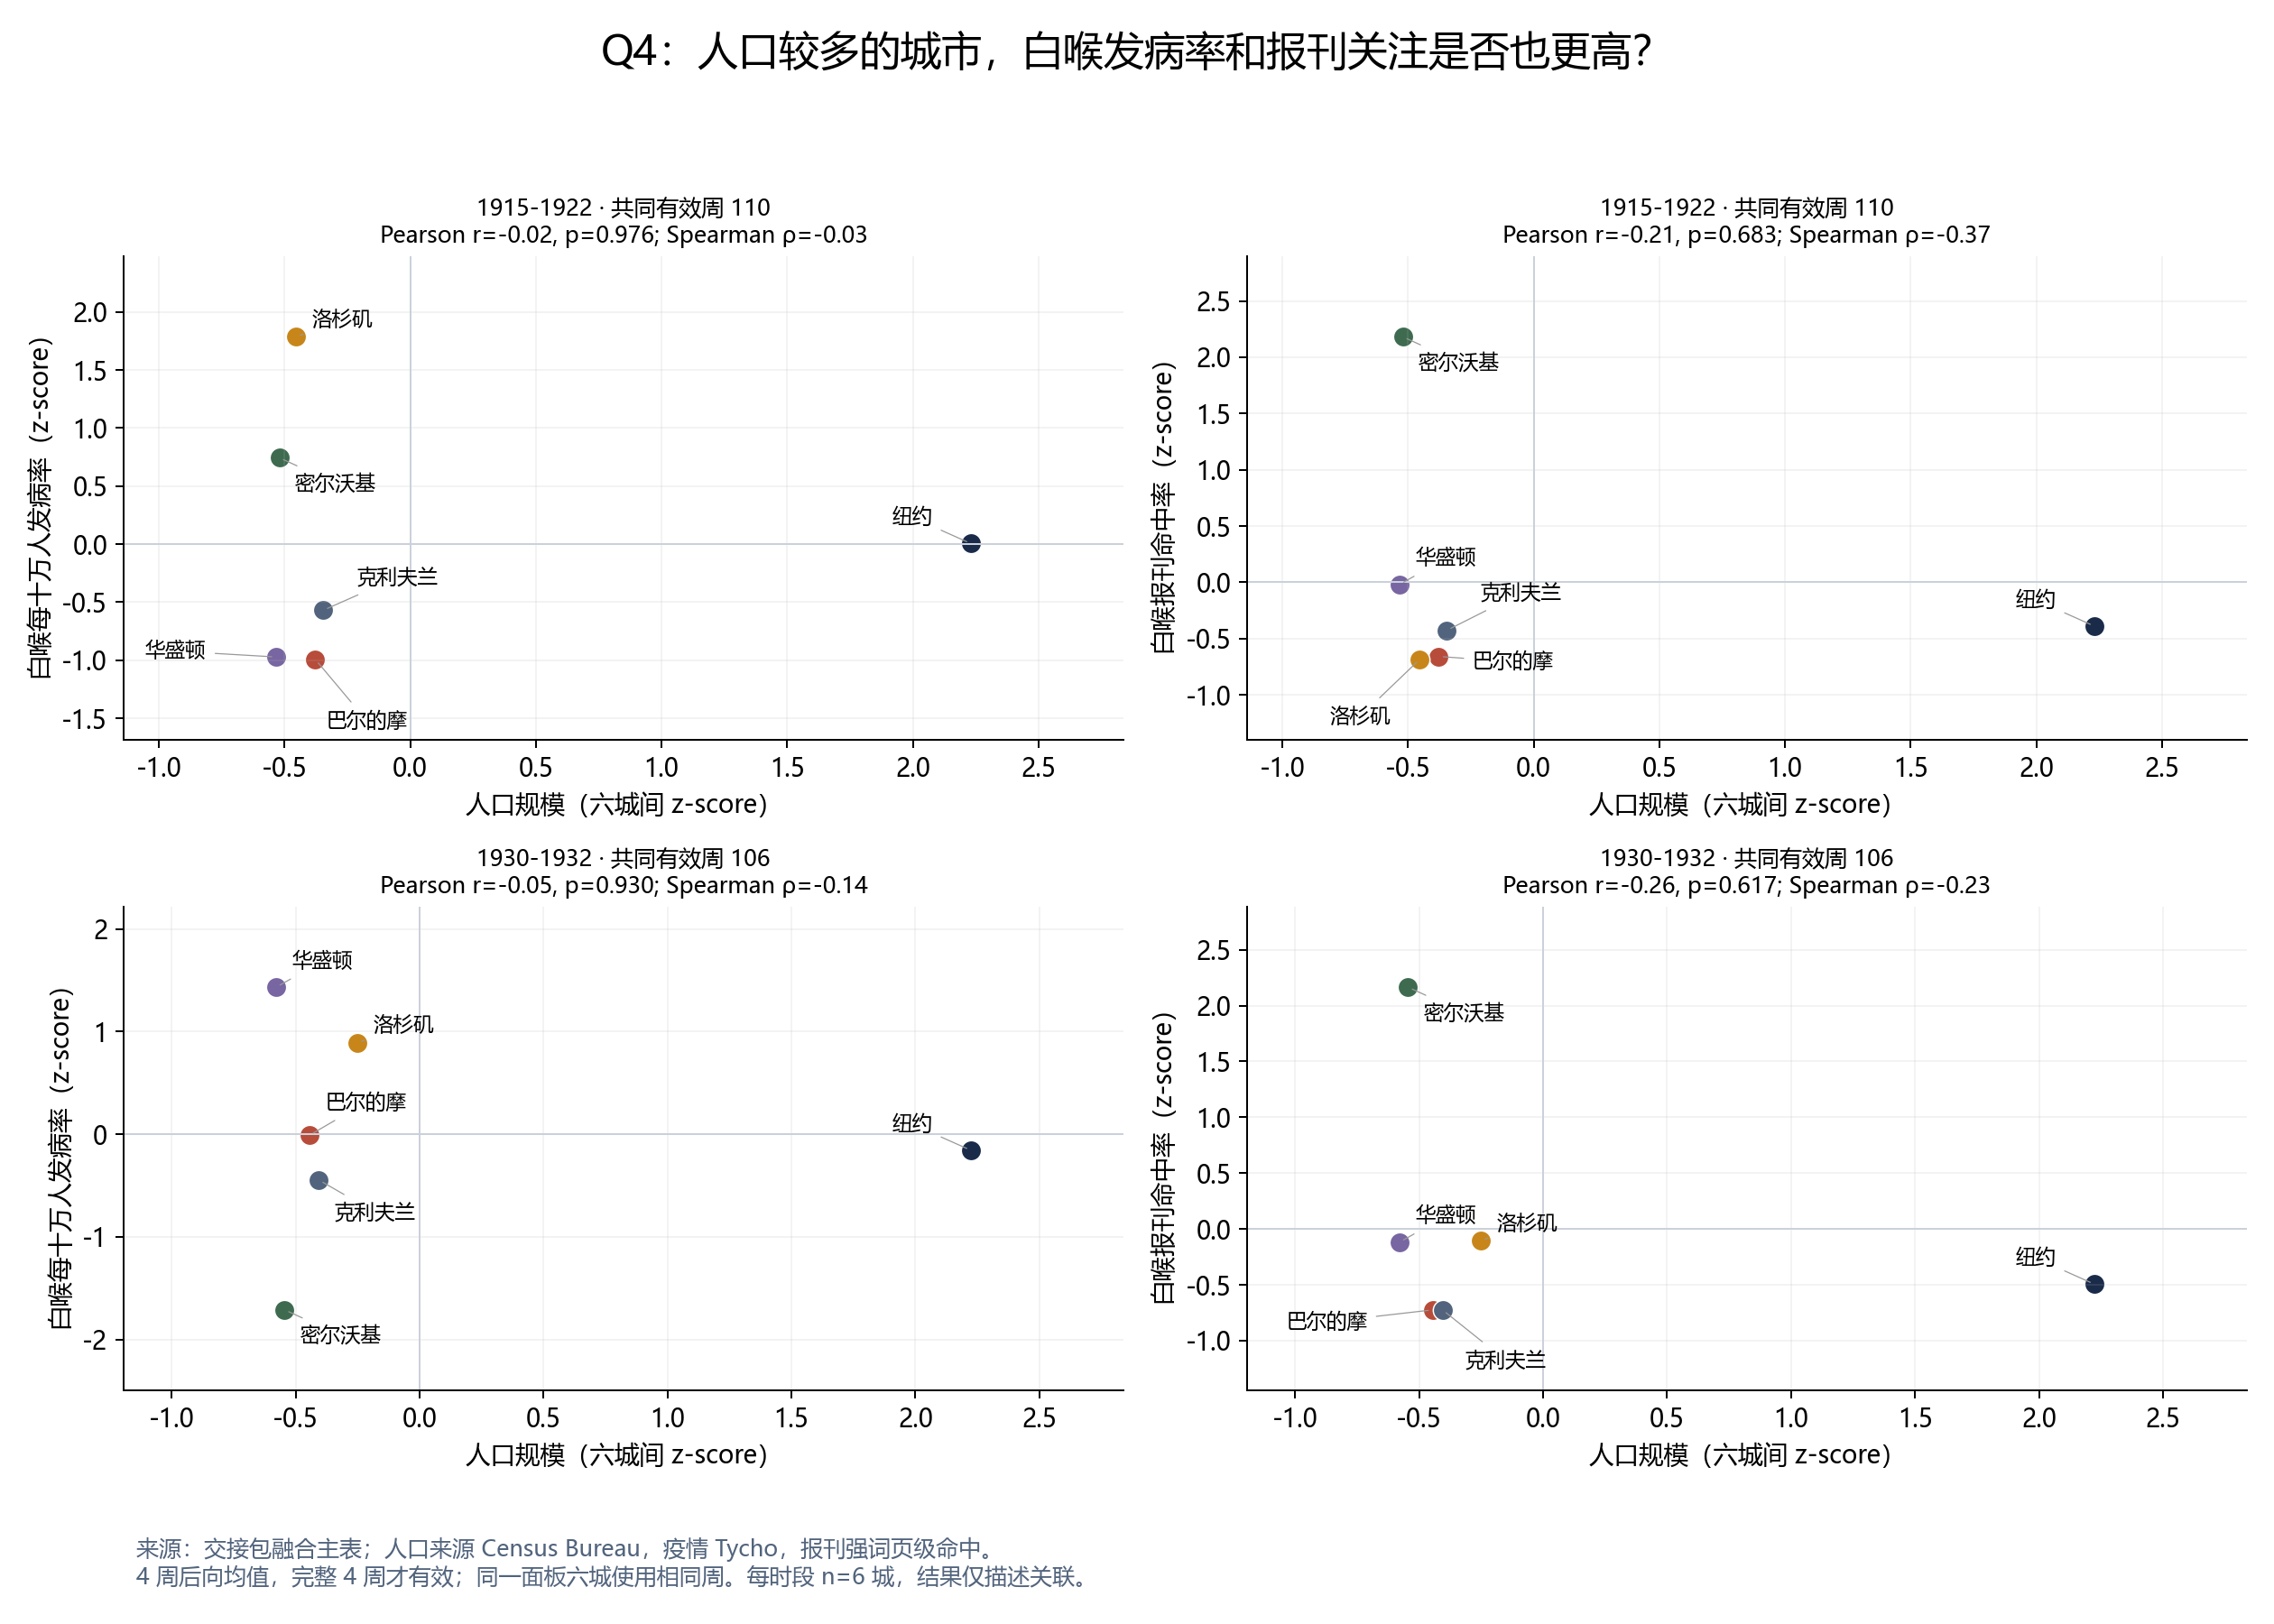

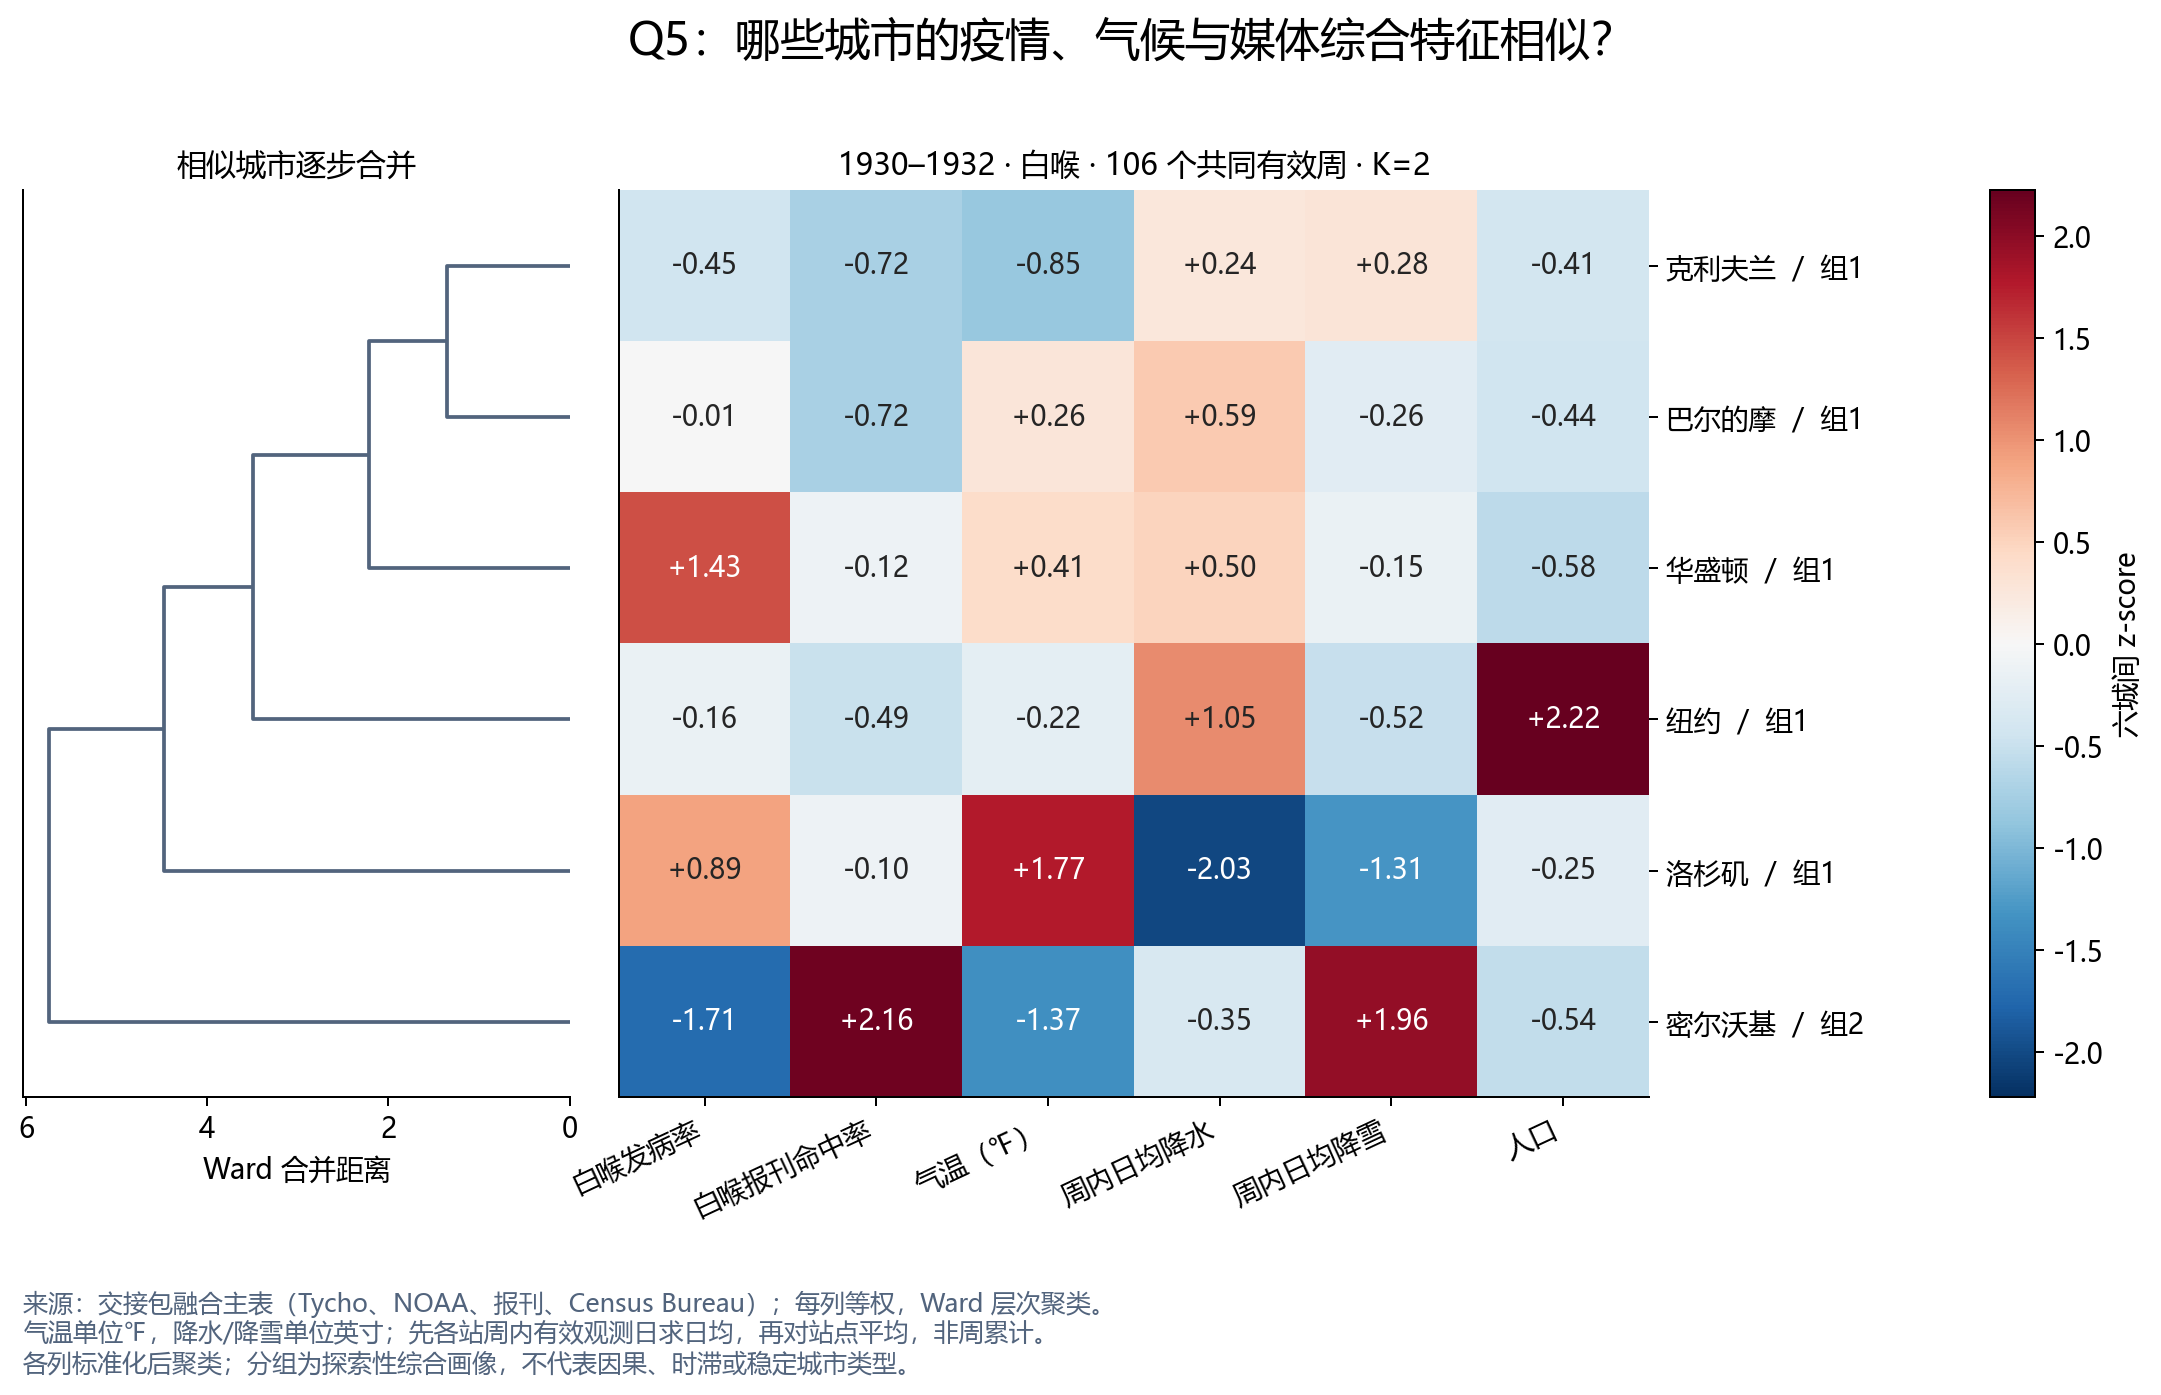

In [6]:
analyze.main()
display(Image(filename=str(ROOT / 'outputs/Q4_城市对比.png')))
display(Image(filename=str(ROOT / 'outputs/Q5_城市聚类.png')))

## 6. 检查结论与稳健性

Pearson和Spearman方向不一致时需如实解释；ARI低说明分组依赖设置。不要把六城聚类说成普遍城市规律。

In [7]:
display(pd.read_csv(ROOT / 'outputs/q4_correlations.csv'))
display(pd.read_csv(ROOT / 'outputs/q5_sensitivity.csv'))
display(Markdown((ROOT / 'outputs/Q4_Q5_结果摘要.md').read_text(encoding='utf-8')))

,window,metric,n_cities,pearson_r,pearson_p,spearman_r,spearman_p
0,1915-1922,diph_rate_per100k,6,-0.015856,0.976217,-0.028571,0.957155
1,1915-1922,np_diph_rate,6,-0.214571,0.683083,-0.371429,0.468478
2,1930-1932,diph_rate_per100k,6,-0.047009,0.929538,-0.142857,0.787172
3,1930-1932,np_diph_rate,6,-0.261020,0.617362,-0.231908,0.658374


,variant,n_common_weeks,k,silhouette,ari_vs_main,labels,status
0,不做4周平滑,123,2,0.308943,1.0,1/1/1/2/1/1,已执行
1,每周至少10页,0,2,NaN,NaN,NaN,共同有效周不足：0
2,排除人口,106,2,0.407172,1.0,1/1/1/2/1/1,已执行
3,排除气象,106,2,0.409884,1.0,1/1/1/2/1/1,已执行
4,去掉_diph_rate_per100k,106,2,0.315959,1.0,1/1/1/2/1/1,已执行
5,去掉_np_diph_rate,106,2,0.249325,-0.2,1/1/2/1/1/1,已执行
6,去掉_tavg_avg,106,2,0.341376,1.0,1/1/1/2/1/1,已执行
7,去掉_prcp_sum,106,2,0.380151,1.0,1/1/1/2/1/1,已执行
8,去掉_snow_sum,106,2,0.262740,1.0,1/1/1/2/1/1,已执行
9,去掉_population,106,2,0.407172,1.0,1/1/1/2/1/1,已执行


# Q4 结果

人口与白喉发病率：Pearson r=-0.047，p=0.930；Spearman ρ=-0.143，p=0.787。方向一致，但仍需结合六城样本量和逐城剔除结果解读。两种检验均未达到p<0.05，本样本未提供人口规模与该指标显著关联的证据；这不等于证明人口没有影响。

人口与白喉报刊命中率：Pearson r=-0.261，p=0.617；Spearman ρ=-0.232，p=0.658。方向一致，但仍需结合六城样本量和逐城剔除结果解读。两种检验均未达到p<0.05，本样本未提供人口规模与该指标显著关联的证据；这不等于证明人口没有影响。

# Q5 结果

组 1：巴尔的摩、克利夫兰、洛杉矶、纽约、华盛顿。相对偏高：白喉发病率（平均 z=0.34）；相对偏低：白喉报刊命中率（平均 z=-0.43）。

组 2：密尔沃基。相对偏高：白喉报刊命中率（平均 z=2.16）；相对偏低：白喉发病率（平均 z=-1.71）。

K=2，轮廓系数=0.316；对照最低ARI=-0.200。六城小样本、白喉单病种、共同有效周条件下的探索性发现；气象单位与周内日均口径已于2026-10-29据用户转述答复确认，标准化输入数值不变。详见HTML报告。


## 7. 独立核验

通过代表所列计算一致，气象单位与汇总定义来自已记录的用户转述答复；自动核验不代表NOAA原始站点清洗、历史边界和因果关系已经验证。运行失败时停下查看具体检查项。

In [8]:
verify.main()

{
  "all_passed": true,
  "passed": 31,
  "total": 31,
  "checks": [
    {
      "check": "输入文件哈希一致",
      "passed": true,
      "detail": ""
    },
    {
      "check": "主表3450行29列",
      "passed": true,
      "detail": ""
    },
    {
      "check": "城市周主键唯一",
      "passed": true,
      "detail": ""
    },
    {
      "check": "周标签均为周日",
      "passed": true,
      "detail": ""
    },
    {
      "check": "原始30个人口值与清洗表一致",
      "passed": true,
      "detail": ""
    },
    {
      "check": "融合人口符合普查年线性插值",
      "passed": true,
      "detail": "最大误差 0.500000 人（容许整数舍入1人）"
    },
    {
      "check": "flu每十万人率公式",
      "passed": true,
      "detail": "主表保留2位小数；最大绝对差0.004996749"
    },
    {
      "check": "flu强词命中率公式",
      "passed": true,
      "detail": "主表保留2位小数；最大绝对差0.005000000"
    },
    {
      "check": "diph每十万人率公式",
      "passed": true,
      "detail": "主表保留2位小数；最大绝对差0.004995942"
    },
    {
      "check": "diph强词命中率公式",
      "passed": true,
      "detail": "主表保留2位小数；

## 8. 提交前自己检查

1. 打开HTML报告并解释两图。
2. 从人口源卡找到原PDF页码，至少人工核对六城各一行，并记录真实复核范围。
3. 将已确认的气象口径同步给E：℉、英寸，降水降雪为周内日均，不是周累计。
4. 将整包交E；由E决定是否接受白喉范围和分析细则。
5. 按真实使用情况确认AI_USAGE_D.md。